# Comprehensive Quality Assurance & Regression Tests
1. Set `COMPARE_EASYSPIN = False` and run all cells to export parameters and MaRs spectra.

In [82]:
%load_ext autoreload
%autoreload 2
import sys
import os
import math
from importlib import reload

import torch
from torch import nn
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import mars

import pandas as pd
from pathlib import Path
from scipy.io import loadmat, savemat

PARAMETERS = Path("parameters")
EASYSPIN_SPECTRA = Path("easyspin_spectra")
MARS_SPECTRA = Path("mars_spectra")
for folder in (PARAMETERS, EASYSPIN_SPECTRA, MARS_SPECTRA):
    folder.mkdir(exist_ok=True)

COMPARE_EASYSPIN = True

REFERENCE_NAMES = [f"spectra_{i}" for i in range(1, 10)] + ["spectra_9_analytical"]
if COMPARE_EASYSPIN:
    missing = [str((EASYSPIN_SPECTRA / f"{name}.csv").resolve())
               for name in REFERENCE_NAMES
               if not (EASYSPIN_SPECTRA / f"{name}.csv").is_file()]
    if missing:
        raise FileNotFoundError(
            "EasySpin references are missing:\n" + "\n".join(missing)
            + "\nRun easy_spic_checker.m in MATLAB and inspect generation_report.csv."
        )
    print("Comparison mode: all ten EasySpin reference files are present.")
else:
    print("Export mode: writing parameters and MaRs spectra. EasySpin is not run by Python.")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Comparison mode: all ten EasySpin reference files are present.


In [83]:
dtype = torch.float64

In [84]:
def read_csv(name: str):
    path = EASYSPIN_SPECTRA / f"{name}.csv"
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing EasySpin spectrum: {path.resolve()}. "
            "Run easy_spic_checker.m in MATLAB and inspect generation_report.csv."
        )
    data = np.loadtxt(path, delimiter=",", ndmin=2)
    if data.shape[0] < 2 or data.shape[1] != 2 or not np.isfinite(data).all():
        raise ValueError(f"Invalid EasySpin CSV {path.resolve()}: expected finite field/intensity columns.")
    if not np.any(data[:, 1]):
        raise ValueError(f"EasySpin CSV {path.resolve()} contains a zero spectrum; normalization is undefined.")
    return data[:, 0], data[:, 1]


def save_case(name, sample, spectra_creator, fields, spectrum):
    # Export before loading the reference, keeping the original MaRs field grid.
    path = PARAMETERS / f"{name}.mat"
    mars.save(str(path), sample=sample, spectra_creator=spectra_creator,
              field=fields, format_type="easyspin")
    data = loadmat(path, simplify_cells=True)
    data = {key: value for key, value in data.items() if not key.startswith("__")}
    # MATLAB defaults to double; integer arithmetic can corrupt EasySpin grids.
    data["Exp"]["nPoints"] = float(fields.numel())
    data["Exp"]["Harmonic"] = float(spectra_creator.spectra_processor.spectra_integrator.harmonic)
    savemat(path, data)
    np.savetxt(MARS_SPECTRA / f"{name}.csv",
               np.column_stack((fields.detach().cpu(), spectrum.detach().cpu())), delimiter=",")


### System_1

Text(0.5, 1.0, 'spectra_1')

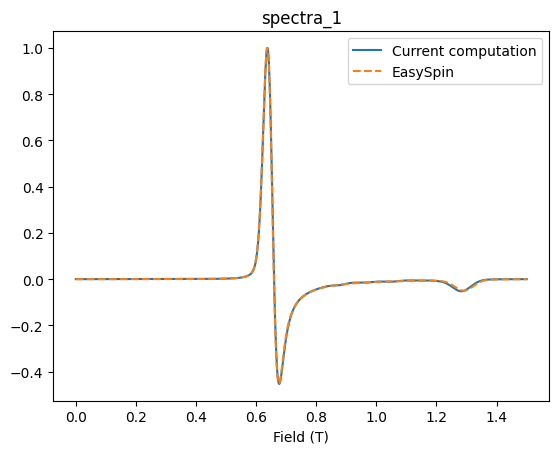

In [85]:
name = "spectra_1"

g_interaction = mars.spin_model.Interaction(2.1, dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([1e6 * 1e6, 1e3 * 1e6], dtype=dtype)
freq = 38.0 * 1e9
gauss = 1e-2
lorentz = 1e-2
ham_strain = 2 * 1e9
temp = 3.5

spin_system = mars.spin_model.SpinSystem(
    electrons=[3/2],
    g_tensors=[g_interaction],
    electron_electron=[(0, 0, DE_interaction)],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(20, 40)
)
computational_details = mars.spectra_manager.ComputationalDetails(res_field_r_tol=1e-4)

spectra_creator = mars.spectra_manager.StationarySpectra(
    computational_details=computational_details,
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)
fields = torch.linspace(0.0, 1.5, 1000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")
plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [86]:
# Parameters and MaRs spectra are saved in the preceding cell.


### System_2

D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\save_procedures\general_procedures.py:52: UserWarning: Not all MaRs objects can be saved to EasySpin format. Computational parameters (e.g. thresholds, EasySpin Opt) are not saved. Such save support will not continue to develop in MaRs
  return format_handlers[format_type](filepath, sample, spectra_creator, field)


Text(0.5, 1.0, 'spectra_2')

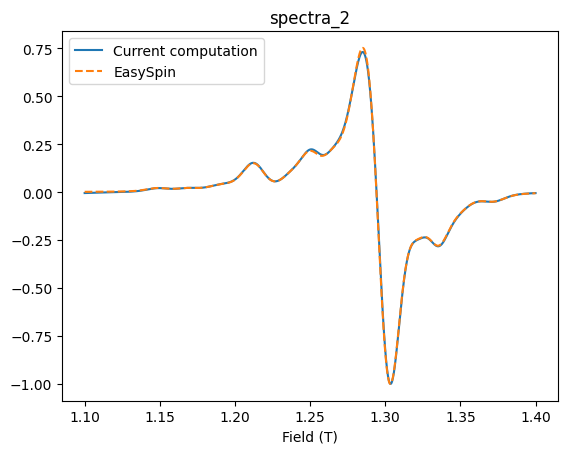

In [88]:
name = "spectra_2"

g_1_interaction = mars.spin_model.Interaction([2.1, 2.2, 2.3], dtype=dtype)
g_2_interaction = mars.spin_model.Interaction(2.1, dtype=dtype)

dipolar_interaction = mars.spin_model.DEInteraction([1e6 * 1e3, 0.0], dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([1e6 * 1e3, 0.0], dtype=dtype)

freq = 38.0 * 1e9
gauss = 1e-2
lorentz = 1e-2
ham_strain = 2 * 1e6 * 100
temp = 100

spin_system = mars.spin_model.SpinSystem(
    electrons=[1/2, 3/2],
    g_tensors=[g_1_interaction, g_2_interaction],
    electron_electron=[(1, 1, DE_interaction), (0, 1, dipolar_interaction)],
    dtype=dtype,
)

mesh = mars.mesher.DelaunayMesh(initial_grid_frequency=20, interpolation_grid_frequency=40, interpolate=True, dtype=dtype)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=mesh
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(1.1, 1.4, 1000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [89]:
# Parameters and MaRs spectra are saved in the preceding cell.


### System_3

Text(0.5, 1.0, 'spectra_3')

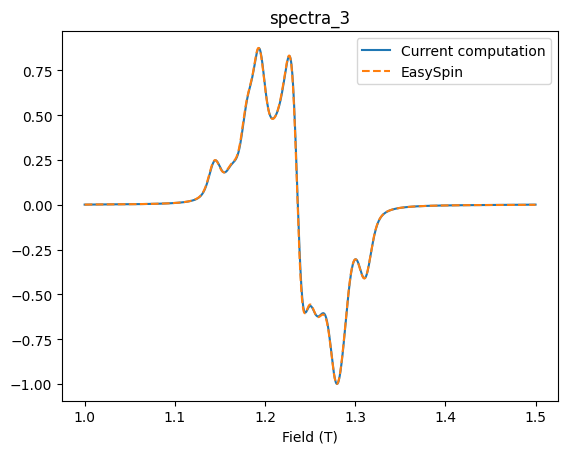

In [90]:
name = "spectra_3"

g_1_interaction = mars.spin_model.Interaction([2.1, 2.2, 2.3], dtype=dtype)
g_2_interaction = mars.spin_model.Interaction([2.1, 2.2, 2.3], dtype=dtype, frame=[1.0, 1.0, 1.0])

J_interaction = mars.spin_model.Interaction(mars.constants.unit_converter(2 * 5, "cm-1_to_Hz"), dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([3 * 1e6 * 1e3, 0.0], dtype=dtype)

freq = 38.0 * 1e9
gauss = 1e-2
lorentz = 1e-2
ham_strain = 0.0
temp = 100

spin_system = mars.spin_model.SpinSystem(
    electrons=[1/2, 2.0/2],
    g_tensors=[g_1_interaction, g_2_interaction],
    electron_electron=[(1, 1, DE_interaction), (0, 1, J_interaction)],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(20, 40)
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(1.0, 1.5, 1000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [91]:
# Parameters and MaRs spectra are saved in the preceding cell.


### System_4

Text(0.5, 1.0, 'spectra_4')

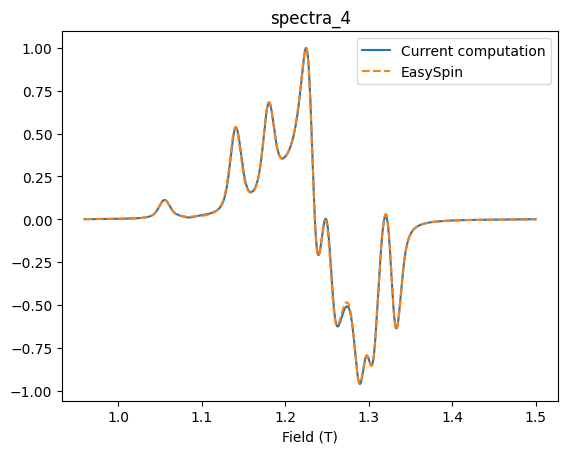

In [92]:
name = "spectra_4"

g_1_interaction = mars.spin_model.Interaction([2.1, 2.2, 2.3], dtype=dtype)
g_2_interaction = mars.spin_model.Interaction([2.1, 2.2, 2.3], dtype=dtype)

J_interaction = mars.spin_model.Interaction(mars.constants.unit_converter(-6, "cm-1_to_Hz"), dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([5.99 * 1e3 * 1e6, 0.89 * 1e3 * 1e6], dtype=dtype)

freq = 38.0 * 1e9
gauss = 1e-2
lorentz = 1e-2
ham_strain = 0.0
temp = 3.5

spin_system = mars.spin_model.SpinSystem(
    electrons=[1/2, 1.0/1.0],
    g_tensors=[g_1_interaction, g_2_interaction],
    electron_electron=[(1, 1, DE_interaction), (0, 1, J_interaction)],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(20, 40)
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(0.96, 1.5, 3000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [93]:
# mars.save(".\example_parameters.mat", sample=sample, spectra_creator=spectra_creator, field=fields, format_type="easyspin")

#import pandas as pd
#data_frame = pd.DataFrame({"field": fields, "spec": spectrum})
#data_frame.to_csv(f".\easy_spin_checked\{name}.csv", header=False, index=False)

### System_5

Text(0.5, 1.0, 'spectra_5')

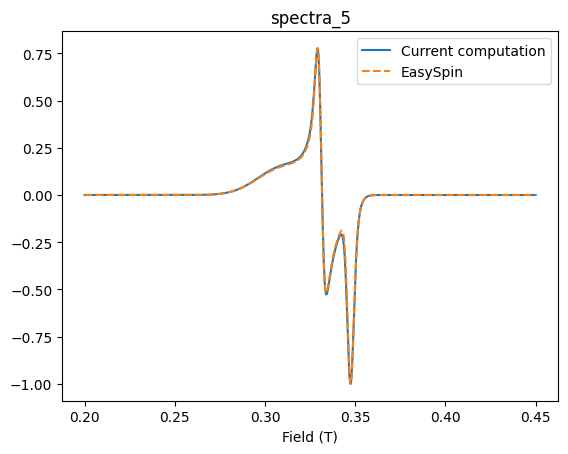

In [94]:
name = "spectra_5"

g_interaction = mars.spin_model.Interaction([2.12, 2.02, 2.30], dtype=dtype)


freq = 9.81 * 1e9
gauss = 0.0
lorentz = 0.0
ham_strain = torch.tensor([100, 100, 1e3], dtype=dtype) * 1e6
temp = 293

spin_system = mars.spin_model.SpinSystem(
    electrons=[1/2],
    g_tensors=[g_interaction],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(20,40)
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(0.2, 0.45, 1000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [95]:
# Parameters and MaRs spectra are saved in the preceding cell.


### System_6

Text(0.5, 1.0, 'spectra_6')

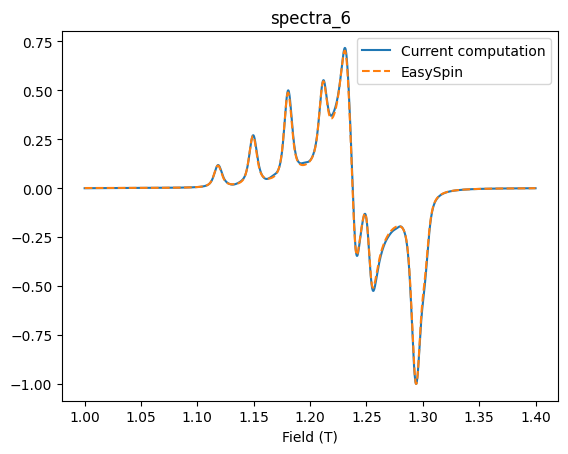

In [96]:
name = "spectra_6"

g_interaction = mars.spin_model.Interaction([2.1, 2.2, 2.3], dtype=dtype)
hyperfine_interaction = mars.spin_model.Interaction([10 * 1e6, 10 * 1e6, 1e3 * 1e6], dtype=dtype)

freq = 38.0 * 1e9
gauss = 5e-3
lorentz = 5e-3
ham_strain = 0.0
temp = 293

spin_system = mars.spin_model.SpinSystem(
    electrons=[1/2],
    nuclei=["14N", "14N"],
    g_tensors=[g_interaction],
    electron_nuclei=[(0, 0, hyperfine_interaction), (0, 1, hyperfine_interaction)],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(20,40)
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(1.0, 1.4, 1500, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [97]:
# Parameters and MaRs spectra are saved in the preceding cell.


### System_7

Text(0.5, 1.0, 'spectra_7')

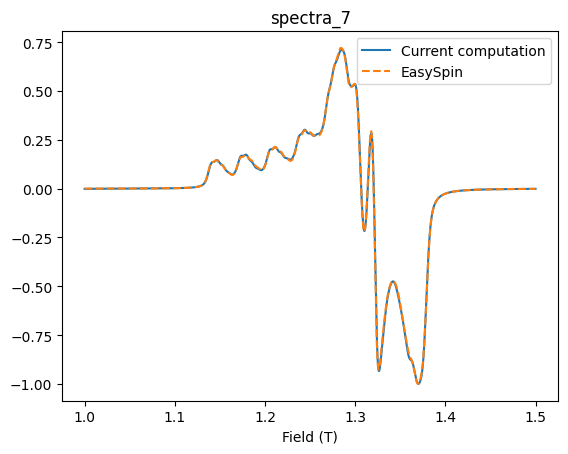

In [98]:
name = "spectra_7"

g_interaction = mars.spin_model.Interaction([2.0, 2.1, 2.2], dtype=dtype)
hyperfine_interaction = mars.spin_model.Interaction([100.0 * 1e6, 100 * 1e6, 1e3 * 1e6], dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([-1.0e8, 0.0], dtype=dtype)


freq = 38.0 * 1e9
gauss = 5e-3
lorentz = 5e-3
ham_strain = 0.0
temp = 3.5

spin_system = mars.spin_model.SpinSystem(
    electrons=[5/2],
    nuclei=["55Mn"],
    g_tensors=[g_interaction],
    electron_electron=[(0, 0, DE_interaction)],
    electron_nuclei=[(0, 0, hyperfine_interaction)],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(25, 25)
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(1.0, 1.5, 2000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [99]:
# Parameters and MaRs spectra are saved in the preceding cell.


### System 8

D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\spectra_manager\res_line_solvers\res_field_algorithm.py:344: UserWarning: Near-degenerate energy levels were detected in this spin system. Resonance-field results may require additional convergence checks.
Increase the orientation mesh density; for spherical powder integration, consider increasing opt.integration_level. Tighten the resonance-field tolerance by decreasing opt.res_field_r_tol (a larger value is less accurate), and increase opt.res_field_split_max_iterations if necessary.
For time-resolved EPR, the rotating-wave approximation (RWA) may be unreliable because secularization can become invalid near degenerate levels. Prefer the kinetic-rate approach (CoupledTimeSpectra) or the direct propagator approach (DensityTimeSpectra with populator='propagator' and hamiltonian_mode='direct'). Alternatively, compare CW spectra with and without secularization (hamiltonian_mode='direct' versus 'secular').
  derivatives_low = self._compute

Text(0.5, 1.0, 'spectra_8')

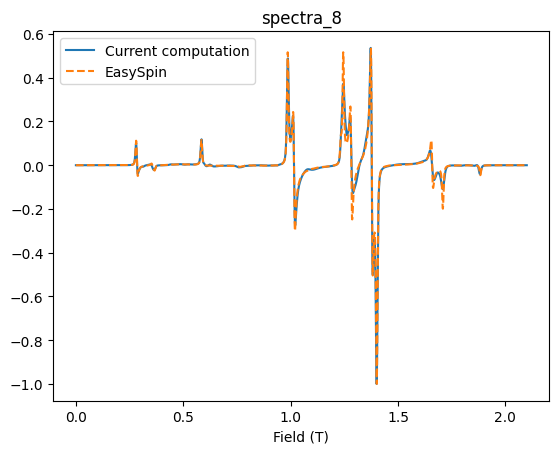

In [100]:
name = "spectra_8"

g_interaction = mars.spin_model.Interaction([2.0, 2.06, 2.2], dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([1e10, 0.0], dtype=dtype)


freq = 38.0 * 1e9
gauss = 5e-3
lorentz = 5e-3
ham_strain = 1e7
temp = 293.0

spin_system = mars.spin_model.SpinSystem(
    electrons=[3/2],
    g_tensors=[g_interaction],
    electron_electron=[(0, 0, DE_interaction)],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(20, 40)
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(0.0, 2.1, 2000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)

save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

In [101]:
# Parameters and MaRs spectra are saved in the preceding cell.


### System 9

Text(0.5, 1.0, 'spectra_9')

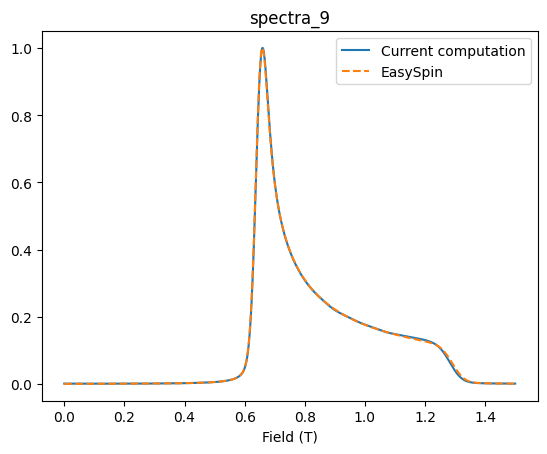

In [102]:
name = "spectra_9"

g_interaction = mars.spin_model.Interaction(2.1, dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([1e6 * 1e6, 1e3 * 1e6], dtype=dtype)
freq = 38.0 * 1e9
gauss = 1e-2
lorentz = 1e-2
ham_strain = 2 * 1e9
temp = 3.5

spin_system = mars.spin_model.SpinSystem(
    electrons=[3/2],
    g_tensors=[g_interaction],
    electron_electron=[(0, 0, DE_interaction)],
    dtype=dtype,
)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=(20, 40)
)


spectra_creator = mars.spectra_manager.StationarySpectra(
    harmonic=0,
    sample=sample,
    freq=freq,
    temperature=temp,
    dtype=dtype,
)

fields = torch.linspace(0.0, 1.5, 1000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)


save_case(name, sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name)
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")

plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")

### Computattional details check

Text(0.5, 1.0, 'spectra_9')

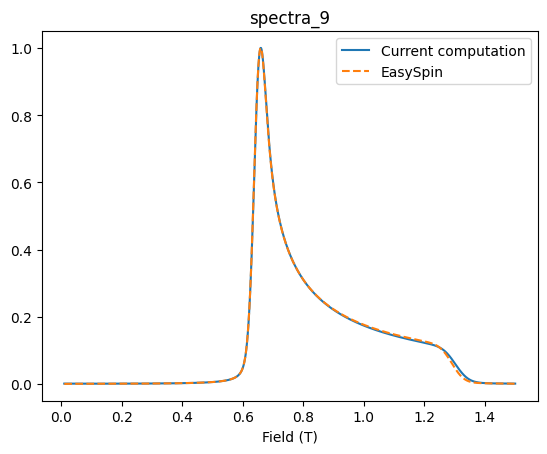

In [103]:
name = "spectra_9"

g_interaction = mars.spin_model.Interaction(2.1, dtype=dtype)
DE_interaction = mars.spin_model.DEInteraction([1e6 * 1e6, 1e3 * 1e6], dtype=dtype)
freq = 38.0 * 1e9
gauss = 1e-2
lorentz = 1e-2
ham_strain = 2 * 1e9
temp = 3.5

spin_system = mars.spin_model.SpinSystem(
    electrons=[3/2],
    g_tensors=[g_interaction],
    electron_electron=[(0, 0, DE_interaction)],
    dtype=dtype,
)

mesh = mars.mesher.AxialMesh(initial_grid_frequency=23, interpolation_grid_frequency=40, dtype=dtype)

sample = mars.spin_model.SolidSample(
    base_spin_system=spin_system,
    gauss=gauss,
    lorentz=lorentz,
    ham_strain=ham_strain,
    dtype=dtype,
    mesh=mesh
)

computational_details = mars.spectra_manager.ComputationalDetails(integration_computation_method="analytical")

spectra_creator = mars.spectra_manager.StationarySpectra(
    sample=sample,
    harmonic=0,
    freq=freq,
    temperature=temp,
    computational_details=computational_details,
    dtype=dtype,
)

fields = torch.linspace(0.01, 1.5, 1000, dtype=dtype)
spectrum = spectra_creator(sample, fields=fields)


save_case(name + "_analytical", sample, spectra_creator, fields, spectrum)

spectrum = spectrum / torch.max(torch.abs(spectrum))
plt.plot(fields, spectrum, "-", label="Current computation")

if COMPARE_EASYSPIN:
    reference_fields, easy_spin_out = read_csv(name + "_analytical")
    easy_spin_out = easy_spin_out / np.max(np.abs(easy_spin_out))
    plt.plot(reference_fields, easy_spin_out, "--", label="EasySpin")


plt.xlabel("Field (T)")
plt.legend()
plt.title(f"{name}")